In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
import string
import re
from collections import Counter
pd.set_option('display.max_colwidth', 200)

In [ ]:
os.chdir("[REDACTED]")  # Personal directory path removed for privacy

In [3]:
f = 'IncludedItems-r1.csv'
df = pd.read_csv(f, dtype=str)
df['Year'] = df['Year'].str.strip()
df.loc[df['Year']=='', 'Year'] = np.nan
df['Year'] = df['Year'].astype('Int64')
print(df['Included'].unique())
df = df.rename(columns={'ID': 'EPPIReviewer ID'})
print(df['EPPIReviewer ID'].nunique(), df.shape)
df.head()

['I']
266 (266, 5)


,Included,EPPIReviewer ID,ShortTitle,Title,Year
0,I,110105526,Ajiferuke (2020),Correction and retraction practices in library and information science journals,2020
1,I,130735248,Akbulut (2026),Scientific ghosts: Life after retraction - A case of Nature Index journals,2026
2,I,110101889,Al-Ghareeb (2018),Retraction of publications in nursing and midwifery research: A systematic review.,2018
3,I,133670847,Alabrese (2023),Bad Science: Retractions and Media Coverage,2023
4,I,133670355,Altunisik (2026),From publication to retraction: A systematic analysis of retraction dynamics in multiple sclerosis and related demyelinating diseases,2026


In [4]:
f = 'data/PostRetractionCitationData_20261119-updated.csv'
included = pd.read_csv(f)
print(included.shape)
included.head(1)

(222, 18)


,What is the citation for the paper?,EPPIReviewer ID,Does this paper consider subjects of study?,Please specify - Selected Choice,What is the sampling methodology? - Selected Choice,What is the sampling methodology? - Other - Text,DataSource_Publications,DataSource_Publications_Other,DataSource_Citations,DataSource_Citations_Other,"Does this paper consider citation sentiment (e.g., positive-neutral-negative) or awareness (retraction status mentioned/non-mentioned)?","For publications that assessed citation sentiment and/or awareness, what taxonomies were used? - Selected Choice","For publications that assessed citation sentiment and/or awareness, what taxonomies were used? - Other - Text",Does this paper measure or describe epistemic harm manifesting from post-retraction citations? - Selected Choice,WashoutPeriod,WashoutPeriod_FreeText,Does this study report both pre and post-retraction citation or citations of retracted vs. unretracted publications?,Does the study compare pre- and post-retraction citation rates or retracted vs. unretracted citation rates?
0,Ajiferuke (2020) Correction and retraction practices in library and information science journals. Journal of Librarianship and Information Science,110105526,Yes,Library and Information Science,Subject related,NaN,Web of Science,NaN,Web of Science,NaN,Yes,Awareness (aware/unaware);Location (introduction/methods/results/discussion),NaN,No,The authors include a washout period,1 year after retraction,"Yes, pre- and post-retraction citations",Yes


In [5]:
included_ids = included['EPPIReviewer ID'].tolist()
print(len(included_ids))
included_ids[:2]

222


['110105526', '130735248']

In [6]:
f = 'data/PostRetractionCitationData_20261119-EH_cleaned.csv'
data = pd.read_csv(f)
data = data.rename(columns={"What is the paper's EPPIReviewer ID?": "EPPIReviewer ID"})
print(data.shape)
data = data.merge(df[['EPPIReviewer ID', 'Year']], how='left')
print(data.shape)

data = data.loc[data['EPPIReviewer ID'].isin(included_ids)]

print(data.shape, data['EPPIReviewer ID'].nunique())
data.head(2)

(226, 20)
(226, 21)
(222, 21) 222


,What is the citation for the paper?,EPPIReviewer ID,Does this paper consider subjects of study?,Please specify - Selected Choice,What is the sampling methodology? - Selected Choice,What is the sampling methodology? - Other - Text,sampling_methodology_consolidated,DataSource_Publications,DataSource_Publications_Other,DataSource_Citations,...,"Does this paper consider citation sentiment (e.g., positive-neutral-negative) or awareness (retraction status mentioned/non-mentioned)?","For publications that assessed citation sentiment and/or awareness, what taxonomies were used? - Selected Choice","For publications that assessed citation sentiment and/or awareness, what taxonomies were used? - Other - Text",Does this paper measure or describe epistemic harm manifesting from post-retraction citations? - Selected Choice,WashoutPeriod,WashoutPeriod_FreeText,WashoutPeriod_Cleaned,Does this study report both pre and post-retraction citation or citations of retracted vs. unretracted publications?,Does the study compare pre- and post-retraction citation rates or retracted vs. unretracted citation rates?,Year
0,Ajiferuke (2020) Correction and retraction practices in library and information science journals. Journal of Librarianship and Information Science,110105526,Yes,Library and Information Science,Subject related,NaN,Subject related,Web of Science,NaN,Web of Science,...,Yes,Awareness (aware/unaware);Location (introduction/methods/results/discussion),NaN,No,The authors include a washout period,1 year after retraction,1 year after retraction,"Yes, pre- and post-retraction citations",Yes,2020
1,"Akbulut, M. (2026). Scientific ghosts: Life after retraction‚ÄîA case of Nature Index journals. Journal of Information Science. https://doi.org/10.1177/01655515261424867",130735248,No,NaN,Database-specific,NaN,Database-specific,Other,Nature Index,Open Citations' COCI;Web of Science,...,Yes,Sentiment (positive/negative);Location (introduction/methods/results/discussion),NaN,No,The authors include a washout period,Following calendar year after retraction,NaN,"Yes, pre- and post-retraction citations",Yes,2026


In [7]:
yrna = data.loc[data['Year'].isna()]
print(yrna.shape)
yrna = yrna[['What is the citation for the paper?', 'EPPIReviewer ID', 'Year']].copy()
yrna

(3, 21)


,What is the citation for the paper?,EPPIReviewer ID,Year
7,An analysis of citations.. (Gabehart) An analysis of citations to retracted articles in the scientific literature.,110238073,<NA>
89,Janavi and Moradi (2019). The fate of Middle Eastern countries' retracted articles on health,Zotero1,<NA>
124,Memon et al. (2026). Are Widely Known Findings Easier to Retract?,Zotero2,<NA>


In [8]:
yrna_eppi_ids = yrna['EPPIReviewer ID'].tolist()
df.loc[df['EPPIReviewer ID'].isin(yrna_eppi_ids)]

,Included,EPPIReviewer ID,ShortTitle,Title,Year
6,I,110238073,An analysis of citations... (Gabehart),An analysis of citations to retracted articles in the scientific literature,<NA>


In [9]:
df.loc[df['ShortTitle']=='Balhara (2015)']

,Included,EPPIReviewer ID,ShortTitle,Title,Year
16,I,110102186,Balhara (2015),A study exploring attributes and nature of the retracted literature on mental disorders.,2015


In [10]:
df.loc[df['ShortTitle'].str.startswith('Memon')]

,Included,EPPIReviewer ID,ShortTitle,Title,Year


In [11]:
# {EPPI ID: Year}
yr_dict = {
    '110238073': 2005,
    '10102186': 2015,
    'Zotero1': 2019,
    'Zotero2': 2026,
    #'130734869': 2025,
}

In [12]:
data.head(1)

,What is the citation for the paper?,EPPIReviewer ID,Does this paper consider subjects of study?,Please specify - Selected Choice,What is the sampling methodology? - Selected Choice,What is the sampling methodology? - Other - Text,sampling_methodology_consolidated,DataSource_Publications,DataSource_Publications_Other,DataSource_Citations,...,"Does this paper consider citation sentiment (e.g., positive-neutral-negative) or awareness (retraction status mentioned/non-mentioned)?","For publications that assessed citation sentiment and/or awareness, what taxonomies were used? - Selected Choice","For publications that assessed citation sentiment and/or awareness, what taxonomies were used? - Other - Text",Does this paper measure or describe epistemic harm manifesting from post-retraction citations? - Selected Choice,WashoutPeriod,WashoutPeriod_FreeText,WashoutPeriod_Cleaned,Does this study report both pre and post-retraction citation or citations of retracted vs. unretracted publications?,Does the study compare pre- and post-retraction citation rates or retracted vs. unretracted citation rates?,Year
0,Ajiferuke (2020) Correction and retraction practices in library and information science journals. Journal of Librarianship and Information Science,110105526,Yes,Library and Information Science,Subject related,NaN,Subject related,Web of Science,NaN,Web of Science,...,Yes,Awareness (aware/unaware);Location (introduction/methods/results/discussion),NaN,No,The authors include a washout period,1 year after retraction,1 year after retraction,"Yes, pre- and post-retraction citations",Yes,2020


In [13]:
for eppi_id, py in yr_dict.items():
    data.loc[data['EPPIReviewer ID']==eppi_id, 'Year'] = py

In [14]:
data.loc[data['Year'].isna()]

,What is the citation for the paper?,EPPIReviewer ID,Does this paper consider subjects of study?,Please specify - Selected Choice,What is the sampling methodology? - Selected Choice,What is the sampling methodology? - Other - Text,sampling_methodology_consolidated,DataSource_Publications,DataSource_Publications_Other,DataSource_Citations,...,"Does this paper consider citation sentiment (e.g., positive-neutral-negative) or awareness (retraction status mentioned/non-mentioned)?","For publications that assessed citation sentiment and/or awareness, what taxonomies were used? - Selected Choice","For publications that assessed citation sentiment and/or awareness, what taxonomies were used? - Other - Text",Does this paper measure or describe epistemic harm manifesting from post-retraction citations? - Selected Choice,WashoutPeriod,WashoutPeriod_FreeText,WashoutPeriod_Cleaned,Does this study report both pre and post-retraction citation or citations of retracted vs. unretracted publications?,Does the study compare pre- and post-retraction citation rates or retracted vs. unretracted citation rates?,Year


In [15]:
data.isna().sum().to_frame()

,0
What is the citation for the paper?,0
EPPIReviewer ID,0
Does this paper consider subjects of study?,0
Please specify - Selected Choice,64
What is the sampling methodology? - Selected Choice,0
What is the sampling methodology? - Other - Text,212
sampling_methodology_consolidated,0
DataSource_Publications,0
DataSource_Publications_Other,197
DataSource_Citations,0


# Data Sources

In [16]:
col0 = 'EPPIReviewer ID'
col1 = 'DataSource_Publications'
col2 = 'DataSource_Publications_Other'
col3 = 'DataSource_Citations'
col4 = 'DataSource_Citations_Other'

source_count_prep = data[[col0, col1, col2, col3, col4]].copy()
source_count_prep.info()

<class 'pandas.core.frame.DataFrame'>
Index: 222 entries, 0 to 225
Data columns (total 5 columns):
 #   Column                         Non-Null Count  Dtype 
---  ------                         --------------  ----- 
 0   EPPIReviewer ID                222 non-null    object
 1   DataSource_Publications        222 non-null    object
 2   DataSource_Publications_Other  25 non-null     object
 3   DataSource_Citations           222 non-null    object
 4   DataSource_Citations_Other     18 non-null     object
dtypes: object(5)
memory usage: 10.4+ KB


In [17]:
punct = f"[{re.escape(string.punctuation)}]"
cond1 = source_count_prep['DataSource_Publications'].str.contains(punct, na=False)
cond2 = source_count_prep['DataSource_Publications_Other'].str.contains(punct, na=False)

data_source_pubs_multi0 = source_count_prep.loc[(cond1)]['DataSource_Publications'].unique().tolist()
data_source_pubs_multi1 = source_count_prep.loc[(cond2)]['DataSource_Publications_Other'].unique().tolist()

data_source_pubs_multi = data_source_pubs_multi0 + data_source_pubs_multi1
data_source_pubs_multi = list(set(data_source_pubs_multi))
print(len(data_source_pubs_multi))
data_source_pubs_multi

49


['PubMed;Web of Science',
 'CNKI; Wanfang; NSTL Degree; CALIS Degree; National Library; Docin.com; Doc88; Baidu Library',
 'PubMed;PubMed Central;Retraction Watch',
 'Google Scholar;PubMed;Web of Science',
 'CINAHL;Google Scholar;PubMed;Retraction Watch',
 'InCites (Clarivate)',
 'Retraction Watch;Web of Science;MEDLINE;Other',
 'Retraction Watch;Scopus;Web of Science;Other',
 'Embase;Google Scholar;MEDLINE;Retraction Watch',
 'Google Scholar;PubMed;Retraction Watch;Web of Science;Other',
 'Embase;PubMed;Retraction Watch',
 'PubMed;PubMed Central',
 'Cochrane Library;Embase;MEDLINE;PubMed;Retraction Watch;Other',
 'Tufts CEA Registry;Database of Abstracts of Reviews of Effects;NHS Economic Evaluation Database;Google Scholar',
 'LILACS (Latin American and Caribbean Literature in Health Sciences)',
 'MEDLINE;Retraction Watch',
 'Web of Science;Other',
 'PubMed;Retraction Watch;Scopus;Web of Science;Other',
 'science.com',
 'Web of Science;MEDLINE',
 'ScienceDirect;Retraction Watch',
 'Sc

In [18]:
data_source_pubs_otr = source_count_prep.loc[~source_count_prep['DataSource_Publications_Other'].isna()]
data_source_pubs_otr = data_source_pubs_otr['DataSource_Publications_Other'].unique().tolist()
data_source_pubs_otr

['Nature Index',
 'Crossref',
 'Cochrane Central Register of Controlled Trials (CENTRAL)',
 'PsycINFO',
 'Crossref;OpenAlex',
 'LILACS (Latin American and Caribbean Literature in Health Sciences)',
 'Feet of Clay Detector',
 'Semantic Scholar',
 'KoreaMed',
 'CNKI; Wanfang; NSTL Degree; CALIS Degree; National Library; Docin.com; Doc88; Baidu Library',
 'Amend Platform',
 'Tufts CEA Registry;Database of Abstracts of Reviews of Effects;NHS Economic Evaluation Database;Google Scholar',
 'The Lens;OpenAlex;Crossref',
 'SciELO',
 'scite',
 'InCites (Clarivate)',
 'EBSCO',
 'Biblioteca Virtual em Saude',
 'CB&R website',
 'VITALITY Study I database',
 'Faculty Opinions/F1000',
 'PubPeer',
 'science.com',
 'Amend platform']

In [19]:
punct = f"[{re.escape(string.punctuation)}]"
cond1 = source_count_prep['DataSource_Citations'].str.contains(punct, na=False)
cond2 = source_count_prep['DataSource_Citations_Other'].str.contains(punct, na=False)

data_source_cits_multi0 = source_count_prep.loc[(cond1)]['DataSource_Citations'].unique().tolist()
data_source_cits_multi1 = source_count_prep.loc[(cond2)]['DataSource_Citations_Other'].unique().tolist()

data_source_cits_multi = data_source_cits_multi0 + data_source_cits_multi1
data_source_cits_multi = list(set(data_source_cits_multi))
print(len(data_source_cits_multi))
data_source_cits_multi

21


['Google Scholar;Scopus',
 'Web of Science;Microsoft Academic Graph',
 "Open Citations' COCI;Web of Science",
 'Korean Citation Index (KCI)',
 "Open Citations' COCI",
 'InCites (Clarivate)',
 'PubMed;PubMed Central',
 'Web of Science;Other',
 'Scopus;Web of Science',
 'PubMed;Scopus;Web of Science',
 'Google Scholar;Scopus;Web of Science',
 'Scopus;Other',
 'Google Scholar;Web of Science;PubMed',
 'Google Scholar;PubMed',
 "Microsoft Academic Graph;Open Citations' COCI",
 'PubMed Central;Other',
 'Google Scholar;Web of Science',
 'Dimensions;Web of Science',
 'Korean Medical Citation Index (KoMCI)',
 'Altmetric;Overton;Crossref',
 'HowNet;Wanfang;Baidu Academic Citation']

In [20]:
source_count_prep = source_count_prep.fillna('NA')

source_count = [['EPPI_ID', '#PubSources', 'PubSources', '#CitSources', 'CitSources']]
for row in source_count_prep.values.tolist():
    eppi_id = row[0]
    
    if row[2] == 'CNKI; Wanfang; NSTL Degree; CALIS Degree; National Library; Docin.com; Doc88; Baidu Library':
        row[2] = 'Mainland China doctoral dissertation and master’s theses databases'
    if row[2] == 'Retraction Watch was used not to IDENTIFY articles but to confirm retraction status and to get reasons for retraction. " In addition, the presence of a retraction notice in both Scopus and Web of Science and on the journal\'s platform was checked, and where no retraction notice could be retrieved from these two sources, the Retraction Watch database was also used."':
        row[2] = 'NA'
    if row[4] == 'HowNet;Wanfang;Baidu Academic Citation':
        row[4] = 'HowNet+Wanfang+Baidu Academic Citation'
    
    pub_info = row[1].split(';') + row[2].split(';')
    pub_info = [info.strip() for info in pub_info]
    cit_info = row[3].split(';') + row[4].split(';')
    cit_info = [info.strip() for info in cit_info]
    
    pub_info = [info for info in pub_info if info not in ['NA', 'Other']]
    cit_info = [info for info in cit_info if info not in ['NA', 'Other']]
    
    nih_ori = ['US Office of Research Integrity', 'NIH Office of Research Integrity', 
               'ORI Newsletter, NIH Guide for Grants an Contracts website', 'NIH Investigation']
    for nih_ori_var in nih_ori:
        if nih_ori_var in pub_info:
            nih_ori_var_idx = pub_info.index(nih_ori_var)
            pub_info[nih_ori_var_idx] = 'NIH Office of Research Integrity'
    
    pub_info.sort()
    cit_info.sort()
    
    n_pub_sources = len(pub_info)
    n_cit_sources = len(cit_info)
    
    pub_sources = ';'.join(pub_info)
    cit_sources = ';'.join(cit_info)
    
    if 'Not reported' in pub_info:
        if len(pub_info) > 1:
            print(f'ID: {eppi_id}, pub_info: {pub_info}')
        else:
            n_pub_sources = 'Not reported'
    if 'Not reported' in cit_info:
        if len(cit_info) > 1:
            print(f'ID: {eppi_id}, cit_info: {cit_info}')
        else:
            n_cit_sources = 'Not reported'

    if 'Not Reported' in pub_info+cit_info:
        print(f'ID: {eppi_id}, cit_info: {cit_info}')
        print(f'ID: {eppi_id}, pub_info: {pub_info}')
            
    source_count.append([eppi_id, n_pub_sources, pub_sources, n_cit_sources, cit_sources])
    
source_count = pd.DataFrame(source_count[1:], columns=source_count[0])
source_count

,EPPI_ID,#PubSources,PubSources,#CitSources,CitSources
0,110105526,1,Web of Science,1,Web of Science
1,130735248,1,Nature Index,2,Open Citations' COCI;Web of Science
2,133670847,1,Retraction Watch,1,Scopus
3,110101889,2,MEDLINE;Retraction Watch,Not reported,Not reported
4,133670355,1,PubMed,1,Web of Science
...,...,...,...,...,...
217,110104346,2,Retraction Watch;Web of Science,1,Web of Science
218,133670576,1,Retraction Watch,1,OpenAlex
219,130735347,1,Amend platform,1,Dimensions
220,110101930,3,PubMed;Retraction Watch;Web of Science,1,Web of Science


In [21]:
pub_source_count = source_count.groupby(['#PubSources'])[['EPPI_ID']].count()
pub_source_count = pub_source_count.reset_index().rename(columns={'EPPI_ID': '#Included Studies'})
pub_source_count['%'] = pub_source_count['#Included Studies']/pub_source_count['#Included Studies'].sum()*100
pub_source_count['%'] = pub_source_count['%'].round(1)

pub_source_count_tot = pub_source_count[['#Included Studies', '%']].sum().to_frame().T
pub_source_count_tot['#PubSources'] = 'total'

pub_source_count = pd.concat([pub_source_count, pub_source_count_tot])
pub_source_count['#Included Studies'] = pub_source_count['#Included Studies'].astype(int)
pub_source_count

,#PubSources,#Included Studies,%
0,1,148,66.7
1,2,24,10.8
2,3,16,7.2
3,4,8,3.6
4,5,4,1.8
5,6,4,1.8
6,7,1,0.5
7,Not reported,17,7.7
0,total,222,100.1


In [22]:
single_pub_source_ids = source_count.loc[source_count['#PubSources']==1]['EPPI_ID'].tolist()
sources_prep = source_count.loc[source_count['EPPI_ID'].isin(single_pub_source_ids)]['PubSources'].tolist()
sources = []
for prep in sources_prep:
    sources += prep.split(';')
    
sources_pub_single = Counter(sources)
sources_pub_single_df = pd.DataFrame({'PubSource': sources_pub_single.keys(), 
                                      '#Included_studies': sources_pub_single.values()})
sources_pub_single_df = sources_pub_single_df.sort_values(by='#Included_studies', ascending=False)
print(sources_pub_single_df.shape, sources_pub_single_df['#Included_studies'].sum())
sources_pub_single_df

(21, 2) 148


,PubSource,#Included_studies
2,Retraction Watch,50
0,Web of Science,32
3,PubMed,31
7,Scopus,9
6,MEDLINE,8
10,Google Scholar,2
5,ScienceDirect,2
4,Crossref,1
8,Feet of Clay Detector,1
9,KoreaMed,1


In [23]:
cit_source_count = source_count.groupby(['#CitSources'])[['EPPI_ID']].count()
cit_source_count = cit_source_count.reset_index().rename(columns={'EPPI_ID': '#Included Studies'})
cit_source_count['%'] = cit_source_count['#Included Studies']/cit_source_count['#Included Studies'].sum()*100
cit_source_count['%'] = cit_source_count['%'].round(1)

cit_source_count_tot = cit_source_count[['#Included Studies', '%']].sum().to_frame().T
cit_source_count_tot['#CitSources'] = 'total'

cit_source_count = pd.concat([cit_source_count, cit_source_count_tot])
cit_source_count['#Included Studies'] = cit_source_count['#Included Studies'].astype(int)

cit_source_count

,#CitSources,#Included Studies,%
0,1,173,77.9
1,2,26,11.7
2,3,6,2.7
3,Not reported,17,7.7
0,total,222,100.0


In [24]:
single_cit_source_ids = source_count.loc[source_count['#CitSources']==1]['EPPI_ID'].tolist()

sources_prep = source_count.loc[source_count['EPPI_ID'].isin(single_cit_source_ids)]['CitSources'].tolist()

sources = []
for prep in sources_prep:
    sources += prep.split(';')
    
sources_cit_singe = Counter(sources)
sources_cit_singe_df = pd.DataFrame({'CitSource': sources_cit_singe.keys(), 
                                     '#Included_studies': sources_cit_singe.values()})
sources_cit_singe_df = sources_cit_singe_df.sort_values(by='#Included_studies', ascending=False)
print(sources_cit_singe_df.shape, sources_cit_singe_df['#Included_studies'].sum())
sources_cit_singe_df

(22, 2) 173


,CitSource,#Included_studies
0,Web of Science,82
1,Scopus,39
2,Google Scholar,26
8,Open Citations' COCI,3
7,PubMed,2
20,Dimensions,2
9,PubMed Central,2
21,OpenAlex,2
3,ScienceDirect,2
6,Feet of Clay Detector,1


In [25]:
#Table 4

sources_prep = source_count['PubSources'].tolist()
sources = []
for prep in sources_prep:
    sources += prep.split(';')
    
sources_pub = Counter(sources)
sources_pub_df = pd.DataFrame({'PubSource': sources_pub.keys(), 
                               '#Included_studies': sources_pub.values()})
sources_pub_df = sources_pub_df.sort_values(by='#Included_studies', ascending=False)
print(sources_pub_df.shape)
sources_pub_df

(38, 2)


,PubSource,#Included_studies
2,Retraction Watch,90
4,PubMed,64
0,Web of Science,60
9,Scopus,24
3,MEDLINE,19
5,Not reported,17
7,Embase,12
12,Google Scholar,12
6,Cochrane Library,6
15,PubMed Central,4


In [26]:
# Table 4
pub_sources_other = set(sources_pub_df.loc[sources_pub_df['#Included_studies']<=2]['PubSource'].tolist())

pub_sources_other_df = [['eppi_id', 'PubSource']]
for row in source_count_prep.values.tolist():
    eppi_id = row[0]
    
    if row[2] == 'CNKI; Wanfang; NSTL Degree; CALIS Degree; National Library; Docin.com; Doc88; Baidu Library':
        row[2] = 'Mainland China doctoral dissertation and master’s theses databases'
    if row[2] == 'Retraction Watch was used not to IDENTIFY articles but to confirm retraction status and to get reasons for retraction. " In addition, the presence of a retraction notice in both Scopus and Web of Science and on the journal\'s platform was checked, and where no retraction notice could be retrieved from these two sources, the Retraction Watch database was also used."':
        row[2] = 'NA'
    if row[4] == 'HowNet;Wanfang;Baidu Academic Citation':
        row[4] = 'HowNet+Wanfang+Baidu Academic Citation'
    
    pub_info = row[1].split(';') + row[2].split(';')
    pub_info = [info.strip() for info in pub_info]

    pub_info_intersection = set(pub_info).intersection(pub_sources_other)
    if len(pub_info_intersection) > 0:
        for pub_source in pub_info_intersection:
            pub_sources_other_df.append([eppi_id, pub_source])

pub_sources_other_df = pd.DataFrame(pub_sources_other_df[1:], columns=pub_sources_other_df[0])

pub_sources_other_df_g = pub_sources_other_df.groupby(['eppi_id'])['PubSource'].apply(list).to_frame()
pub_sources_other_df_g['#PubSource'] = pub_sources_other_df_g['PubSource'].str.len()
pub_sources_other_df_g = pub_sources_other_df_g.sort_values(by='#PubSource', ascending=False)
print(pub_sources_other_df_g.shape)
pub_sources_other_df_g

(24, 2)


,PubSource,#PubSource
eppi_id,,
130734629,"[NHS Economic Evaluation Database, Tufts CEA Registry, Database of Abstracts of Reviews of Effects]",3
130735274,"[OpenAlex, The Lens]",2
110101895,[Cochrane Central Register of Controlled Trials (CENTRAL)],1
110102154,[Biblioteca Virtual em Saude],1
130735347,[Amend platform],1
130735253,[LILACS (Latin American and Caribbean Literature in Health Sciences)],1
130735248,[Nature Index],1
130735247,[EBSCO],1
130735238,[Amend Platform],1


In [27]:
# Table 4
pub_sources_other_df_g_s = pub_sources_other_df_g.loc[pub_sources_other_df_g['#PubSource']==1].copy()
pub_sources_other_df_g_s['PubSource'] = pub_sources_other_df_g_s['PubSource'].str[0]
pub_sources_other_df_g_s_l = pub_sources_other_df_g_s['PubSource'].unique().tolist()
pub_sources_other_df_g_s_l.sort()
print(pub_sources_other_df_g_s_l)

['Amend Platform', 'Amend platform', 'Biblioteca Virtual em Saude', 'CB&R website', 'Cochrane Central Register of Controlled Trials (CENTRAL)', 'EBSCO', 'Faculty Opinions/F1000', 'Feet of Clay Detector', 'InCites (Clarivate)', 'KoreaMed', 'LILACS (Latin American and Caribbean Literature in Health Sciences)', 'Mainland China doctoral dissertation and master’s theses databases', 'Nature Index', 'OpenAlex', 'PsycINFO', 'PubPeer', 'SciELO', 'Semantic Scholar', 'VITALITY Study I database', 'science.com', 'scite']


In [28]:
med_dbs = ['PubMed', 'MEDLINE', 'Embase', 'Cochrane Library', 'PubMed Central', 
           'CINAHL', 'Biblioteca Virtual em Saude', 'VITALITY Study I database', 'KoreaMed', 'Tufts CEA Registry', 
           'LILACS (Latin American and Caribbean Literature in Health Sciences)', 
           'Cochrane Central Register of Controlled Trials (CENTRAL)']
print(len(med_dbs))

med_dbs_check = []

n_studies_used_med_pubs = 0
for row in source_count_prep.values.tolist():
    eppi_id = row[0]
    
    if row[2] == 'CNKI; Wanfang; NSTL Degree; CALIS Degree; National Library; Docin.com; Doc88; Baidu Library':
        row[2] = 'Mainland China doctoral dissertation and master’s theses databases'
    if row[2] == 'Retraction Watch was used not to IDENTIFY articles but to confirm retraction status and to get reasons for retraction. " In addition, the presence of a retraction notice in both Scopus and Web of Science and on the journal\'s platform was checked, and where no retraction notice could be retrieved from these two sources, the Retraction Watch database was also used."':
        row[2] = 'NA'
    if row[4] == 'HowNet;Wanfang;Baidu Academic Citation':
        row[4] = 'HowNet+Wanfang+Baidu Academic Citation'
    
    pub_info = row[1].split(';') + row[2].split(';')
    pub_info = [info.strip() for info in pub_info]

    med_intersection = set(med_dbs).intersection(set(pub_info))
    if len(med_intersection) > 0:
        n_studies_used_med_pubs += 1

        med_dbs_check += list(med_intersection)

med_dbs_check = list(set(med_dbs_check))
print(len(med_dbs_check))
n_studies_used_med_pubs

12
12


84

In [29]:
# Table 5
sources_prep = source_count['CitSources'].tolist()
sources = []
for prep in sources_prep:
    sources += prep.split(';')
    
sources_cit = Counter(sources)
sources_cit_df = pd.DataFrame({'CitSource': sources_cit.keys(), 
                               '#Included_studies': sources_cit.values()})
sources_cit_df = sources_cit_df.sort_values(by='#Included_studies', ascending=False)
print(sources_cit_df.shape)
sources_cit_df

(29, 2)


,CitSource,#Included_studies
0,Web of Science,104
2,Scopus,55
4,Google Scholar,38
3,Not reported,17
11,PubMed,6
1,Open Citations' COCI,5
14,PubMed Central,4
7,Semantic Scholar,3
12,Microsoft Academic Graph,3
18,Dimensions,3


In [30]:
# Table 5

cit_sources_other = set(sources_cit_df.loc[sources_cit_df['#Included_studies']<2]['CitSource'].tolist())

cit_sources_other_df = [['eppi_id', 'CitSource']]
for row in source_count_prep.values.tolist():
    eppi_id = row[0]
    
    if row[2] == 'CNKI; Wanfang; NSTL Degree; CALIS Degree; National Library; Docin.com; Doc88; Baidu Library':
        row[2] = 'Mainland China doctoral dissertation and master’s theses databases'
    if row[2] == 'Retraction Watch was used not to IDENTIFY articles but to confirm retraction status and to get reasons for retraction. " In addition, the presence of a retraction notice in both Scopus and Web of Science and on the journal\'s platform was checked, and where no retraction notice could be retrieved from these two sources, the Retraction Watch database was also used."':
        row[2] = 'NA'
    if row[4] == 'HowNet;Wanfang;Baidu Academic Citation':
        row[4] = 'HowNet+Wanfang+Baidu Academic Citation'
    
    cit_info = row[3].split(';') + row[4].split(';')
    cit_info = [info.strip() for info in cit_info]

    cit_info_intersection = set(cit_info).intersection(cit_sources_other)
    if len(cit_info_intersection) > 0:
        for cit_source in cit_info_intersection:
            cit_sources_other_df.append([eppi_id, cit_source])

cit_sources_other_df = pd.DataFrame(cit_sources_other_df[1:], columns=cit_sources_other_df[0])

cit_sources_other_df_g = cit_sources_other_df.groupby(['eppi_id'])['CitSource'].apply(list).to_frame()
cit_sources_other_df_g['#CitSource'] = cit_sources_other_df_g['CitSource'].str.len()
cit_sources_other_df_g = cit_sources_other_df_g.sort_values(by='#CitSource', ascending=False)
print(cit_sources_other_df_g.shape)
cit_sources_other_df_g

(14, 2)


,CitSource,#CitSource
eppi_id,,
133670824,"[Altmetric, Overton, Crossref]",3
110102057,[NIH iCite],1
110105215,[HowNet+Wanfang+Baidu Academic Citation],1
110105289,[InCites (Clarivate)],1
110105588,[Korean Medical Citation Index (KoMCI)],1
110239148,[Altmetrics],1
110239194,[Korean Citation Index (KCI)],1
130734629,[CitationChaser],1
130734632,[VITALITY Study I database],1


In [31]:
# Table 4
cit_sources_other_df_g_s = cit_sources_other_df_g.loc[cit_sources_other_df_g['#CitSource']==1].copy()
cit_sources_other_df_g_s['CitSource'] = cit_sources_other_df_g_s['CitSource'].str[0]
cit_sources_other_df_g_s_l = cit_sources_other_df_g_s['CitSource'].unique().tolist()
cit_sources_other_df_g_s_l.sort()
print(cit_sources_other_df_g_s_l)

['Altmetrics', 'CitationChaser', 'Feet of Clay Detector', 'Google Patents', 'HowNet+Wanfang+Baidu Academic Citation', 'InCites (Clarivate)', 'Korean Citation Index (KCI)', 'Korean Medical Citation Index (KoMCI)', 'NIH iCite', 'PatentsView', 'Publish or Perish', 'The Lens', 'VITALITY Study I database']


# Sampling Methods

In [32]:
q1 = 'What is the sampling methodology? - Selected Choice'
q2 = 'What is the sampling methodology? - Other - Text'
q3 = 'Does this paper consider subjects of study?'
q4 = 'Please specify - Selected Choice'
q5 = 'sampling_methodology_consolidated'
q6 = 'DataSource_Publications'
q7 = 'DataSource_Publications_Other'
sampling = data[['EPPIReviewer ID', q1, q2, q3, q4, q5, q6]].copy()
sampling = sampling.rename(columns={q1: 'sampling_methodology_choice', 
                                    q2: 'sampling_methodology_other_txt', 
                                    q3: 'subject_considered', 
                                    q4: 'subject_info'})
sampling['subject_info_main'] = sampling['subject_info'].str.split('--').str[0]
sampling['sampling_methodology_choice'] = sampling['sampling_methodology_choice'].fillna('NA')
sampling['sampling_methodology_other_txt'] = sampling['sampling_methodology_other_txt'].fillna('NA')
print(sampling.info())
sampling.head()

<class 'pandas.core.frame.DataFrame'>
Index: 222 entries, 0 to 225
Data columns (total 8 columns):
 #   Column                             Non-Null Count  Dtype 
---  ------                             --------------  ----- 
 0   EPPIReviewer ID                    222 non-null    object
 1   sampling_methodology_choice        222 non-null    object
 2   sampling_methodology_other_txt     222 non-null    object
 3   subject_considered                 222 non-null    object
 4   subject_info                       158 non-null    object
 5   sampling_methodology_consolidated  222 non-null    object
 6   DataSource_Publications            222 non-null    object
 7   subject_info_main                  158 non-null    object
dtypes: object(8)
memory usage: 15.6+ KB
None


,EPPIReviewer ID,sampling_methodology_choice,sampling_methodology_other_txt,subject_considered,subject_info,sampling_methodology_consolidated,DataSource_Publications,subject_info_main
0,110105526,Subject related,NA,Yes,Library and Information Science,Subject related,Web of Science,Library and Information Science
1,130735248,Database-specific,NA,No,NaN,Database-specific,Other,NaN
2,133670847,Journal specific,NA,No,NaN,Journal specific,Retraction Watch,NaN
3,110101889,Subject related,NA,Yes,Health and Life Sciences--Nursing and Midwifery,Subject related,Retraction Watch;MEDLINE,Health and Life Sciences
4,133670355,Subject related,NA,Yes,Health and Life Sciences--Neurology,Subject related,PubMed,Health and Life Sciences


In [33]:
sampling['#sampling_methodology'] = sampling['sampling_methodology_consolidated'].str.split(';').str.len()
n_sampling_methodology = sampling.groupby(['#sampling_methodology'])[['EPPIReviewer ID']].count()
print(n_sampling_methodology.shape, n_sampling_methodology['EPPIReviewer ID'].sum())
n_sampling_methodology

(4, 1) 222


,EPPIReviewer ID
#sampling_methodology,
1,165
2,45
3,10
4,2


In [34]:
sampling_methodologies = []
for row in sampling['sampling_methodology_consolidated'].tolist():
    row = row.split(';')
    row = [item.strip() for item in row]
    sampling_methodologies += row
    
sampling_methodologies_count = Counter(sampling_methodologies)

sampling_methodologies_count = pd.DataFrame({'sampling_methodology': list(sampling_methodologies_count.keys()), 
                                             '#Included Studies': list(sampling_methodologies_count.values())})

sampling_methodologies_count = sampling_methodologies_count.sort_values(by=['#Included Studies'], ascending=False)
print(sampling_methodologies_count.shape)
sampling_methodologies_count

(13, 2)


,sampling_methodology,#Included Studies
0,Subject related,108
1,Database-specific,35
6,Specific article(s)/Specific author(s),34
3,Specific country/countries/region,28
5,Publication date,26
7,Publication type/Study design,16
10,Reason for retraction,12
2,Journal specific,11
9,Other,8
4,Open Access status,6


# Research Fields Represented in the Literature

In [35]:
q2 = 'Does this paper consider subjects of study?'
q3 = 'Please specify - Selected Choice'
fields = data[['EPPIReviewer ID', q2, q3]].copy()
print(fields.info())

<class 'pandas.core.frame.DataFrame'>
Index: 222 entries, 0 to 225
Data columns (total 3 columns):
 #   Column                                       Non-Null Count  Dtype 
---  ------                                       --------------  ----- 
 0   EPPIReviewer ID                              222 non-null    object
 1   Does this paper consider subjects of study?  222 non-null    object
 2   Please specify - Selected Choice             158 non-null    object
dtypes: object(3)
memory usage: 6.9+ KB
None


In [36]:
fields.loc[fields[q3].isna()][q2].unique()

array(['No'], dtype=object)

In [37]:
fields[q2].unique()

array(['Yes', 'No'], dtype=object)

In [38]:
fields.loc[(fields[q2]=='Yes')&(fields[q3].isna())]

,EPPIReviewer ID,Does this paper consider subjects of study?,Please specify - Selected Choice


In [39]:
fields.loc[fields[q2]=='No', q3] = 'Field not considered'
fields['field_mjr'] = fields['Please specify - Selected Choice'].str.split('--')
fields['field_mjr'] = fields['field_mjr'].str[0]
fields.info()

<class 'pandas.core.frame.DataFrame'>
Index: 222 entries, 0 to 225
Data columns (total 4 columns):
 #   Column                                       Non-Null Count  Dtype 
---  ------                                       --------------  ----- 
 0   EPPIReviewer ID                              222 non-null    object
 1   Does this paper consider subjects of study?  222 non-null    object
 2   Please specify - Selected Choice             222 non-null    object
 3   field_mjr                                    222 non-null    object
dtypes: object(4)
memory usage: 8.7+ KB


In [40]:
field_mjr_tbl = fields.groupby(['field_mjr'])[['EPPIReviewer ID']].count()
field_mjr_tbl = field_mjr_tbl.rename(columns={'EPPIReviewer ID': '#Included Studies'})

field_mjr_tbl = field_mjr_tbl.sort_values(by='#Included Studies', ascending=False)
print(field_mjr_tbl.shape, field_mjr_tbl['#Included Studies'].sum())
field_mjr_tbl

(13, 1) 222


,#Included Studies
field_mjr,
Health and Life Sciences,130
Field not considered,64
Psychology/Psychiatry,8
Business,5
Engineering and Computer Science,4
Arts and Humanities,2
Chemistry and Biochemistry,2
Social Sciences,2
Environmental Science,1


In [41]:
# Data absent

dfplt = fields.loc[fields['field_mjr']=='Health and Life Sciences'].copy()
dfplt['subfield_studied'] = dfplt[q3].str.split('--')
dfplt['subfield_studied'] = dfplt['subfield_studied'].str[-1]

dfplt = dfplt.groupby(['subfield_studied'])[['EPPIReviewer ID']].count().reset_index()
dfplt = dfplt.rename(columns={'EPPIReviewer ID': '#Included Studies'})
dfplt = dfplt.sort_values(by='#Included Studies', ascending=False)

print(dfplt.shape, dfplt['#Included Studies'].sum())
dfplt

(37, 2) 130


,subfield_studied,#Included Studies
19,No Specialty,39
6,Dental,8
22,Oncology (including Radiation Oncology),8
4,"Cardiology, cardiothoracic and cardiovascular disease",7
20,Nursing and Midwifery,6
1,Anesthesiology,6
3,COVID-19,5
10,Gastroenterology,5
13,Infectious Disease/Clinical Microbiology,3
27,Pharmacy,3


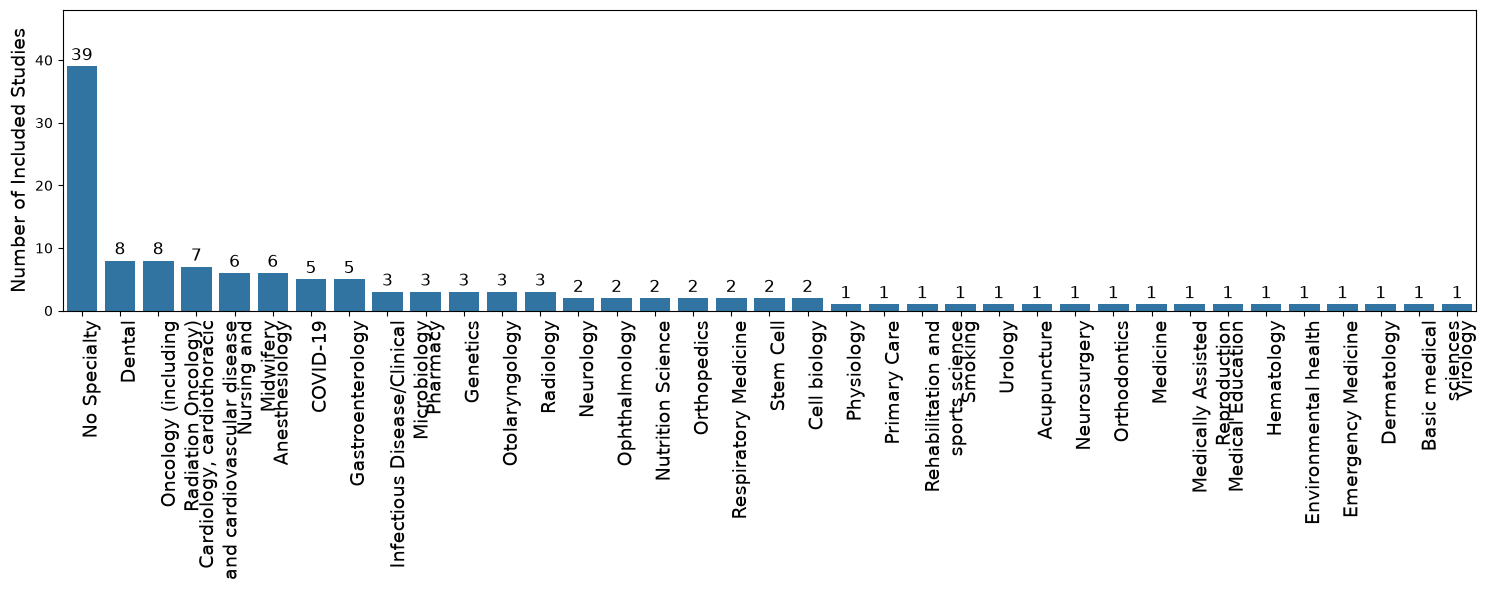

In [42]:
fig, ax = plt.subplots(figsize=(15, 6))

sns.barplot(data=dfplt, x='subfield_studied', y='#Included Studies', ax=ax)

xticks = ax.get_xticks()
xtick_labels = []
for lbl in dfplt['subfield_studied'].tolist():
    lbl_split = lbl.split()
    n_words = len(lbl_split)
    if n_words > 2:
        #print(lbl)
        lbl_str = ' '.join(lbl_split[:2]) + '\n' + ' '.join(lbl_split[2:])
    else:
        lbl_str = lbl
    xtick_labels.append(lbl_str.strip())
    
ax.set_xticks(xticks)
ax.set_xticklabels(xtick_labels, rotation=90, ha='right', va='top', rotation_mode='anchor', size=14)

for xpos, count in zip(xticks, dfplt['#Included Studies'].tolist()):
    ax.text(x=xpos, y=count+1, s=str(count), ha='center', size=12) 
    
ax.set_ylim(0, 48)
ax.set_xlabel('')
ax.set_ylabel('Number of Included Studies', size=14)

plt.tight_layout()

plt.savefig('figs/med_subfields-r1.png')

plt.show()

# Pre-and-post

In [43]:
q1 = 'Does this study report both pre and post-retraction citation or citations of retracted vs. unretracted publications?'
q2 = 'Does the study compare pre- and post-retraction citation rates or retracted vs. unretracted citation rates?'

pre_post = data[['EPPIReviewer ID', q1, q2]].copy()
print(pre_post.info())
pre_post.head()

<class 'pandas.core.frame.DataFrame'>
Index: 222 entries, 0 to 225
Data columns (total 3 columns):
 #   Column                                                                                                                Non-Null Count  Dtype 
---  ------                                                                                                                --------------  ----- 
 0   EPPIReviewer ID                                                                                                       222 non-null    object
 1   Does this study report both pre and post-retraction citation or citations of retracted vs. unretracted publications?  222 non-null    object
 2   Does the study compare pre- and post-retraction citation rates or retracted vs. unretracted citation rates?           164 non-null    object
dtypes: object(3)
memory usage: 6.9+ KB
None


,EPPIReviewer ID,Does this study report both pre and post-retraction citation or citations of retracted vs. unretracted publications?,Does the study compare pre- and post-retraction citation rates or retracted vs. unretracted citation rates?
0,110105526,"Yes, pre- and post-retraction citations",Yes
1,130735248,"Yes, pre- and post-retraction citations",Yes
2,133670847,"Yes, pre- and post-retraction citations;Yes, retracted and unretracted publications",Yes
3,110101889,No,NaN
4,133670355,"Yes, pre- and post-retraction citations",Yes


In [44]:
pre_post['Does this study report both pre and post-retraction citation or citations of retracted vs. unretracted publications?'].unique()

array(['Yes, pre- and post-retraction citations',
       'Yes, pre- and post-retraction citations;Yes, retracted and unretracted publications',
       'No', 'Yes, citations to retracted and unretracted publications'],
      dtype=object)

In [45]:
pre_post_g1 = pre_post.groupby(q1)[['EPPIReviewer ID']].count()
pre_post_g1

,EPPIReviewer ID
Does this study report both pre and post-retraction citation or citations of retracted vs. unretracted publications?,
No,56
"Yes, citations to retracted and unretracted publications",7
"Yes, pre- and post-retraction citations",140
"Yes, pre- and post-retraction citations;Yes, retracted and unretracted publications",19


In [46]:
pre_post.loc[pre_post[q1]!='No'].shape[0]

166

In [47]:
pre_post_g1 = pre_post.groupby(q2)[['EPPIReviewer ID']].count()
pre_post_g1

,EPPIReviewer ID
Does the study compare pre- and post-retraction citation rates or retracted vs. unretracted citation rates?,
No,102
Yes,62


# Washout

In [48]:
washout = data[['EPPIReviewer ID', 'WashoutPeriod', 'WashoutPeriod_FreeText', 'WashoutPeriod_Cleaned']].copy()
washout['WashoutPeriod'].unique()

array(['The authors include a washout period',
       'The authors do not mention washout periods',
       'The authors discuss washout periods, but do not use one'],
      dtype=object)

In [49]:
txt0 = '"Post-retraction citation was defined as any publication that cited a retracted article after retraction notices were published. The date of submission of citing articles was after the date of retraction notice publication. Concerning thosemarticles whose date of submission was unavailable, a publication was considered as post-retraction citation if it was published later than 6 months after the date of retraction"'
txt1 = 'seems to have varied by article - articles were "retracted between 1995 and 2014" "since data were collected on October 2014, and citation that appears from 2015 onwards is definitely a post retraction citation" - reported in each of the 15 cases'
txt2 = 'Approximately one month after retraction'
txt3 = 'Following calendar year after retraction'
txt4 = '1 month following retraction'
txt5 = 'Calendar month after retraction'
txt6 = 'Other: Publication of retraction notice; Following calendar year after retraction'
txt7 = 'Second calendar year following the publication of the last retraction notice (for several retracted papers)'
txt8 = 'Submitted after the publication of retraction notice'

washout['WashoutPeriod2'] = washout['WashoutPeriod_FreeText']

washout.loc[washout['WashoutPeriod_FreeText']==txt0, 'WashoutPeriod2'] = 'Published after the publication of retraction notice'
washout.loc[washout['WashoutPeriod_FreeText']==txt1, 'WashoutPeriod2'] = "Published after sample's final retraction notice"
washout.loc[washout['WashoutPeriod_FreeText']==txt2, 'WashoutPeriod2'] = "1 month after retraction"
washout.loc[washout['WashoutPeriod_FreeText']==txt3, 'WashoutPeriod2'] = "Following calendar year"
washout.loc[washout['WashoutPeriod_FreeText']==txt5, 'WashoutPeriod2'] = "1 month after retraction"
washout.loc[washout['WashoutPeriod_FreeText']==txt6, 'WashoutPeriod2'] = "Following calendar year"

washout.loc[~washout['WashoutPeriod_Cleaned'].isna(), 'WashoutPeriod2'] = washout['WashoutPeriod_Cleaned']

washout.loc[washout['WashoutPeriod_Cleaned']==txt4, 'WashoutPeriod2'] = "1 month after retraction"
washout.loc[washout['WashoutPeriod_Cleaned']==txt7, 'WashoutPeriod2'] = "Second calendar year after sample's final retraction notice"
washout.loc[washout['WashoutPeriod_Cleaned']==txt8, 'WashoutPeriod2'] = "Submission date after retraction notice published"

#washout.loc[~washout['WashoutPeriod_Cleaned'].isna(), 'WashoutPeriod2'] = washout['WashoutPeriod_Cleaned']

washout['WashoutPeriod_FreeText'] = washout['WashoutPeriod_FreeText'].fillna('NA')

In [50]:
washout.loc[washout['WashoutPeriod']=='The authors include a washout period'].shape[0]

65

In [51]:
washout_multi = [
    '1 year, 2 years, and 3 years',
    'Other: Publication of retraction notice; Following calendar year after retraction',
    'within 12 months after retraction; 12-36 months after retraction'
]
washout.loc[washout['WashoutPeriod2'].isin(washout_multi)]

,EPPIReviewer ID,WashoutPeriod,WashoutPeriod_FreeText,WashoutPeriod_Cleaned,WashoutPeriod2


In [52]:
washout.loc[washout['WashoutPeriod2']=='1 month following retraction']

,EPPIReviewer ID,WashoutPeriod,WashoutPeriod_FreeText,WashoutPeriod_Cleaned,WashoutPeriod2


In [53]:
washout_df = washout.groupby(['WashoutPeriod', 'WashoutPeriod2'], dropna=False)[['EPPIReviewer ID']].count()
washout_df = washout_df.sort_values(by=['WashoutPeriod', 'EPPIReviewer ID'], ascending=False)
print(washout_df.shape, washout_df['EPPIReviewer ID'].sum())
washout_df

(15, 1) 222


EPPIReviewer ID
WashoutPeriod                                           WashoutPeriod2                                                                                                                                               
The authors include a washout period                    Following calendar year                                                                                                                                    37
                                                        1 year after retraction                                                                                                                                     6
                                                        1 month after retraction                                                                                                                                    4
                                                        Second calendar year following the year of retraction                                                                                                       4
                                                        6 months after retraction                                                                                                                                   3
                                                        multiple cross-sections                                                                                                                                     3
                                                        Submission date after retraction notice published                                                                                                           2
                                                        2 months after retraction                                                                                                                                   1
                                                        Calendar year after sample's final retraction notice                                                                                                        1
                                                        Calendar year after the publication of the majority of an author's work                                                                                     1
                                                        Comparison between retraction date and the days between a systematic review's search date to an estimated submission date                                   1
                                                        Second calendar year after sample's final retraction notice                                                                                                 1
                                                        Submitted after the publication of retraction notice; if submission date unavaialbe, 6 months after the publication of the retraction notice                1
The authors do not mention washout periods              NaN                                                                                                                                                       156
The authors discuss washout periods, but do not use one NaN                                                                                                                                                         1

In [54]:
washout_df2 = washout_df.reset_index()
washout_df2.loc[washout_df2['WashoutPeriod']=='The authors include a washout period']['EPPIReviewer ID'].sum()

np.int64(65)

In [55]:
37+7+3+4+4+3+2+6

66

In [56]:
washout.loc[washout['WashoutPeriod2']=='multiple cross-sections']

,EPPIReviewer ID,WashoutPeriod,WashoutPeriod_FreeText,WashoutPeriod_Cleaned,WashoutPeriod2
72,110102065,The authors include a washout period,"1 year, 2 years, and 3 years",multiple cross-sections,multiple cross-sections
104,110104998,The authors include a washout period,Calendar year after sample's final retraction notice,multiple cross-sections,multiple cross-sections
193,110102295,The authors include a washout period,within 12 months after retraction; 12-36 months after retraction,multiple cross-sections,multiple cross-sections


# Taxonomies

In [57]:
q1 = 'Does this paper consider citation sentiment (e.g., positive-neutral-negative) or awareness (retraction status mentioned/non-mentioned)?'
q2 = 'For publications that assessed citation sentiment and/or awareness, what taxonomies were used? - Selected Choice'
q3 = 'For publications that assessed citation sentiment and/or awareness, what taxonomies were used? - Other - Text'
taxonomies = data[['EPPIReviewer ID', q1, q2, q3, 'Year']].copy()
taxonomies = taxonomies.rename(columns={q1: 'sentiment_awarness_considered',
                                        q2: 'sentiment_awarness_taxonomies', 
                                        q3: 'sentiment_awarness_taxonomies_freetxt'})
print(taxonomies.info())
taxonomies.head(2)

<class 'pandas.core.frame.DataFrame'>
Index: 222 entries, 0 to 225
Data columns (total 5 columns):
 #   Column                                 Non-Null Count  Dtype 
---  ------                                 --------------  ----- 
 0   EPPIReviewer ID                        222 non-null    object
 1   sentiment_awarness_considered          222 non-null    object
 2   sentiment_awarness_taxonomies          79 non-null     object
 3   sentiment_awarness_taxonomies_freetxt  18 non-null     object
 4   Year                                   222 non-null    Int64 
dtypes: Int64(1), object(4)
memory usage: 18.7+ KB
None


,EPPIReviewer ID,sentiment_awarness_considered,sentiment_awarness_taxonomies,sentiment_awarness_taxonomies_freetxt,Year
0,110105526,Yes,Awareness (aware/unaware);Location (introduction/methods/results/discussion),NaN,2020
1,130735248,Yes,Sentiment (positive/negative);Location (introduction/methods/results/discussion),NaN,2026


In [58]:
taxonomies.loc[~taxonomies['sentiment_awarness_taxonomies_freetxt'].isna()]['sentiment_awarness_taxonomies'].unique()

array(['Other', 'Awareness (aware/unaware);Other',
       'Location (introduction/methods/results/discussion)',
       'Location (introduction/methods/results/discussion);Other',
       'Awareness (aware/unaware);Sentiment (positive/negative);Other'],
      dtype=object)

In [59]:
taxonomies.loc[~taxonomies['sentiment_awarness_taxonomies_freetxt'].isna()]

,EPPIReviewer ID,sentiment_awarness_considered,sentiment_awarness_taxonomies,sentiment_awarness_taxonomies_freetxt,Year
27,110102064,Yes,Other,Acknowledged;Explicitly positive;Implicitly positive,1998
28,110238994,Yes,Other,Acknowledged;Explicitly positive;Implicitly positive,1999
30,110106165,Yes,Awareness (aware/unaware);Other,"Tacit (positive);Substantive (positive) ""tacit positive citation (mention of the paper as, for example, part of a literature review), or substantive positive citation (mention as part of usage in ...",2016
61,110106490,Yes,Other,Acknowledged;Not acknowledged (specific citation of data);Not acknowledged (cited in passing),2015
62,110107256,Yes,Other,"""(a) those that explicitly acknowledged the false nature of the retracted research, (b) those that provided evidence that the authors believed that the original article contained valid research co...",2012
64,133670343,Yes,Other,Sentiment (positive/negative); Location (introduction/methods/results/discussion),2026
69,110105803,Yes,Location (introduction/methods/results/discussion),Inclusion,2018
92,110102092,Yes,Location (introduction/methods/results/discussion);Other,With or without caution,2022
128,110104228,Yes,Other,Related work or use‚ÄîCitations referencing related work or using content from within a retraction.;Comparison of results‚ÄîCompared findings to another paper;Corrections‚ÄîCorrected an article ba...,2024
164,110104139,Yes,Other,Conflicting;Ambiguous;Highly cocited;Orienting reference list;Supporting;Opposition;Skepticism;Uncertainty,2024


In [60]:
taxonomies.loc[taxonomies['sentiment_awarness_considered']=='No']['sentiment_awarness_taxonomies'].unique()

array([nan], dtype=object)

In [61]:
taxonomies.loc[taxonomies['sentiment_awarness_considered']=='No']['sentiment_awarness_taxonomies_freetxt'].unique()

array([nan], dtype=object)

In [62]:
taxonomies_ = []
muti_taxonomies_ = []
has_taxonomies = taxonomies.loc[taxonomies['sentiment_awarness_considered']=='Yes']
print(has_taxonomies.shape)
for i, row in has_taxonomies.iterrows():
    taxonomies_options = row['sentiment_awarness_taxonomies']
    taxonomies_options = taxonomies_options.split(';')
    taxonomies_options.sort()
    if len(taxonomies_options) == 1:
        taxonomies_.append(taxonomies_options[0])
    else:
        taxonomies_.append('Multiple')
        muti_taxonomies_.append(';'.join(taxonomies_options))
        
            
Counter(taxonomies_), sum(list(Counter(taxonomies_).values()))

(79, 5)


(Counter({'Awareness (aware/unaware)': 24,
          'Sentiment (positive/negative)': 20,
          'Multiple': 19,
          'Other': 11,
          'Location (introduction/methods/results/discussion)': 5}),
 79)

In [63]:
19 + 11 + 5

35

In [64]:
taxonomies_df_prep = dict()

has_taxonomies = taxonomies.loc[taxonomies['sentiment_awarness_considered']=='Yes']
for i, row in has_taxonomies.iterrows():
    taxonomies_options = row['sentiment_awarness_taxonomies']
    taxonomies_freetxt = row['sentiment_awarness_taxonomies_freetxt']
    
    taxonomies_options = taxonomies_options.split(';')
    
    if isinstance(taxonomies_freetxt, str):
        taxonomies_freetxt = taxonomies_freetxt.split(';')
    else:
        taxonomies_freetxt = []
    
    for taxonomies_option in taxonomies_options:
        if taxonomies_option not in taxonomies_df_prep:
            taxonomies_df_prep[taxonomies_option] = 1
        else:
            taxonomies_df_prep[taxonomies_option] += 1

taxonomies_df = pd.DataFrame({'Taxonomy': taxonomies_df_prep.keys(), 
                              '#Included Studies':taxonomies_df_prep.values()})
taxonomies_df

,Taxonomy,#Included Studies
0,Awareness (aware/unaware),37
1,Location (introduction/methods/results/discussion),16
2,Sentiment (positive/negative),31
3,Other,17


In [65]:
taxonomy_yn_yr = taxonomies.groupby(['Year', 'sentiment_awarness_considered'])[['EPPIReviewer ID']].count()
taxonomy_yn_yr = taxonomy_yn_yr.rename(columns={'EPPIReviewer ID': '#Included Studies'})
taxonomy_yn_yr = taxonomy_yn_yr.reset_index()
print(taxonomy_yn_yr.loc[taxonomy_yn_yr['sentiment_awarness_considered']=='Yes']['#Included Studies'].max())
taxonomy_yn_yr

12


,Year,sentiment_awarness_considered,#Included Studies
0,1990,No,1
1,1991,Yes,1
2,1992,Yes,1
3,1994,No,1
4,1998,Yes,1
5,1999,Yes,1
6,2005,Yes,1
7,2006,Yes,1
8,2008,No,1
9,2008,Yes,1


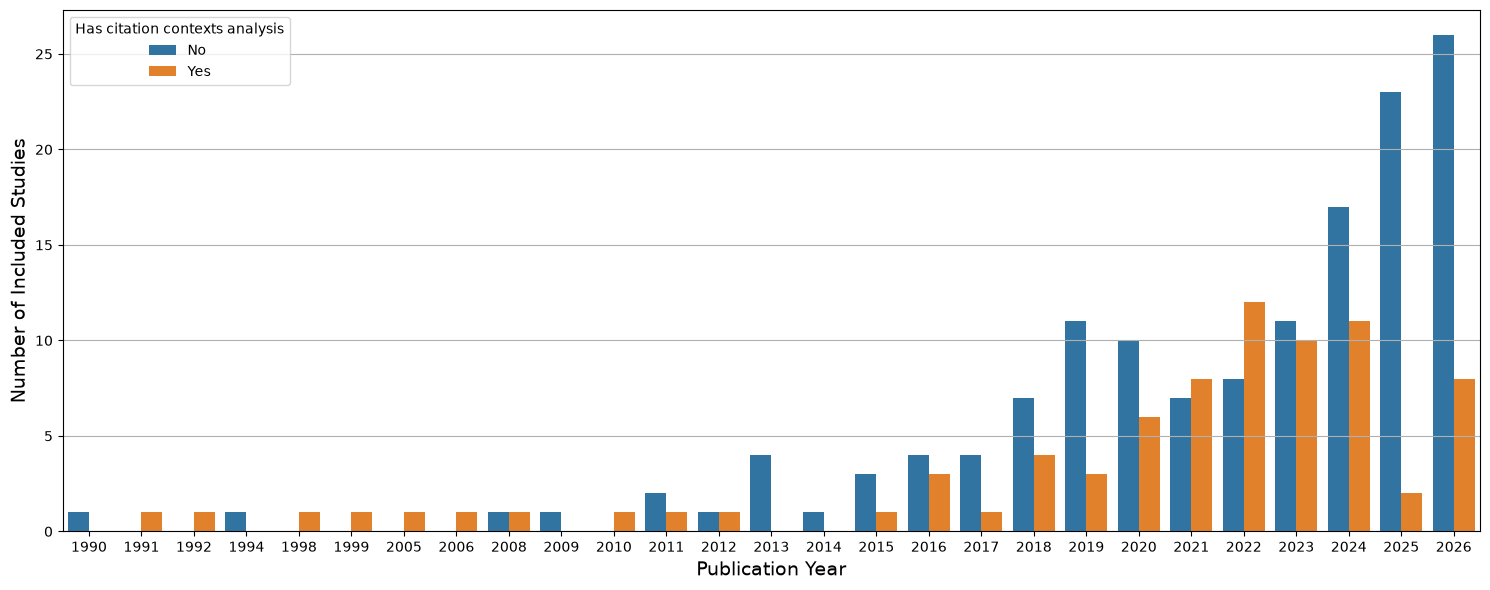

In [66]:
fig, ax = plt.subplots(figsize=(15, 6))

sns.barplot(data=taxonomy_yn_yr, x="Year", y="#Included Studies", hue="sentiment_awarness_considered")

ax.set_xlabel('Publication Year', size=14)
ax.set_ylabel('Number of Included Studies', size=14)

ax.grid(axis='y')
ax.legend(title='Has citation contexts analysis')

plt.tight_layout()
plt.savefig('figs/sentiment_aware_considered-r1.png')
plt.show()